# Map OH Binding Energies on Pt–Ni Alloys


## Goal of the notebook

Let us explore how local environments under a Pt surface create a distribution of OH binding energies in Pt–Ni alloy models.


## Description of the method

ASE builds slabs with a Pt skin and selected Pt–Ni compositions below it. UMA gives energies and forces for the clean and OH covered models. We will use a fixed random seed to create a reproducible set of structures, then compare them with pure Pt and a Pt skin on Ni.

The energy convention appears in the calculation. To connect these distributions with a free energy optimum, we also need consistent reference states and thermochemical corrections.


## What we will do

1. Let us calculate reference adsorption energies for Pt and a Pt skin on Ni.
2. We will build Pt50Ni50 and Pt90Ni10 subsurface ensembles, then relax OH on each fixed slab.
3. We will plot the OH binding distributions and inspect their centers, widths, and sample counts.


In [ ]:
# Install course dependencies only in Google Colab. Local runs use environment.yml.
!if python -c "import google.colab" >/dev/null 2>&1; then pip install -q fairchem-core ase gdown matplotlib numpy; fi

### If the Colab install reports dependency conflicts

Colab may already include `torchvision` and `pytensor`. Installing FairChem can update PyTorch and Numba to versions those packages do not request. This warning alone does not mean the installation failed. These notebooks do not use `torchvision` or PyTensor, so you can leave them installed and continue without restarting the runtime. If a FairChem import or calculation shows an actual error, use that error to guide the next step.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

from ase import Atoms
from ase.build import add_adsorbate, fcc111, molecule
from ase.constraints import FixAtoms
from ase.io import Trajectory
from ase.optimize import BFGS
from ase.visualize import view
from fairchem.core import FAIRChemCalculator
from fairchem.core.units.mlip_unit import MLIPPredictUnit
from IPython.display import display
from pathlib import Path
from torch.serialization import add_safe_globals

In [ ]:
# Standard publication figure sizes in inches
plt.rc("figure", figsize  = (8.25 / 2.54, 8.25 / 2.54))
plt.rc("figure", dpi      = 100)
plt.rc("lines",  linewidth= 4)
plt.rc("font",   size     = 10)
plt.rc("font",   family   = "sans-serif")
plt.rc("axes",   titlesize= 10)
plt.rc("axes",   labelsize= 9)
plt.rc("xtick",  labelsize= 8)
plt.rc("ytick",  labelsize= 8)
plt.rc("legend", fontsize = 8)
plt.rc("figure", titlesize= 10)

pd.options.display.float_format = "{:.2f}".format

The UMA model uses the [FAIR Chemistry License](https://huggingface.co/facebook/UMA/blob/main/LICENSE). Let us read its terms before we use the model. A personal Hugging Face account and access token are part of the full setup. This notebook provides the model file through Google Drive so we can focus on the calculation.


In [ ]:
# Download once into the current folder.
!if [ ! -s uma-s-1p1.pt ]; then gdown 1pw3jkPMWL6CLmpRGhBPdvzoLn4MzpTEX -O uma-s-1p1.pt; fi
if not Path('uma-s-1p1.pt').is_file() or Path('uma-s-1p1.pt').stat().st_size == 0:
    raise FileNotFoundError("Download failed: uma-s-1p1.pt")

In [ ]:
add_safe_globals([slice])  # Permit slice objects stored in the trusted UMA checkpoint.
model_path = "uma-s-1p1.pt"
predictor = MLIPPredictUnit(model_path, device="cpu")
calculator = FAIRChemCalculator(predictor, task_name="oc20")

Let us keep the FCC lattice parameters and adsorbate structures in two dictionaries. Then we can choose a metal or adsorbate by name in the cells below.


In [ ]:
lattice_constants_angstrom = {"Pt": 3.9936, "Ni": 3.565}
adsorbates = {"OH": Atoms("OH", ([0, 0, 0], [0.65, 0.65, 0.4]))}

In [ ]:
# zip pairs items from the supplied lists in the same order.
def mean_lattice_constant(composition):
    """Return the composition-weighted Pt–Ni lattice constant in Å."""
    lattice_constant_angstrom = 0.0
    for fraction, element in zip(composition, elements):
        lattice_constant_angstrom += fraction * lattice_constants_angstrom[element]
    return lattice_constant_angstrom

## Set up the descriptor framework




A descriptor is a material property that helps us organize or predict catalytic behavior. For ORR, an adsorption energy can serve as a descriptor. It gives us one quantity to compare across catalyst models.


OH is one key intermediate in ORR. Its interaction with a catalyst often serves as a descriptor for a broader set of reaction steps. Let us follow how OH adsorbs and leaves the surface, then connect its binding energy with the full energy pathway.


Other ORR descriptors include adsorption energies for O₂, OH, and OOH. Calculations give us these values for each model. We can then ask how they relate to the catalyst behavior.


A volcano plot places a descriptor on the horizontal axis and a measure of activity on the vertical axis. Its peak marks the best value in that model. Strong OH binding can make removal of OH difficult; weak binding can make OH formation difficult. Let us use the plot to see which side each catalyst occupies, then treat it as a guide for later experiments.


A literature example places Pt overlayer catalysts on an ORR volcano.

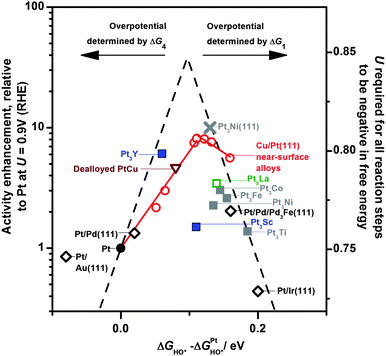

*Figure: Volcano plot for catalysts with Pt overlayers.*

The example workflow is simple: calculate an OH descriptor, locate it on the volcano, then test the prediction with experiments.


The descriptor idea gives us a reason to examine the alloy ensemble. The cited Pt overlayer volcano supplies the reference for energy shifts from pure Pt.


## Calculate pure-metal references




Let us calculate two reference models: Pt(111) and a Ni slab with one Pt layer on top. The Pt skin changes its electronic environment and can shift OH binding from the pure Pt value.


In [ ]:
atoms = fcc111("Pt", (3, 3, 5), a=lattice_constants_angstrom["Pt"], vacuum=10)
atoms.set_constraint(FixAtoms(mask=atoms.get_tags() > 0))
adsorbate = adsorbates["OH"]
add_adsorbate(atoms, adsorbate, height=2.0, position="ontop")
view(atoms, viewer="x3d")

In [ ]:
atoms.pbc = [True, True, True]
atoms.calc = calculator

In [ ]:
optimizer = BFGS(atoms, trajectory="PtOH.traj", logfile="PtOH.log")
optimizer.run(fmax=0.1)

### Check OH on Pt

Inspect the optimized structure and the energy shown above. Which change in geometry or energy matters for the chemical question in this section?

In [ ]:
view(atoms, viewer="x3d")

### Calculate OH binding on a Pt skin over Ni


In [ ]:
atoms = fcc111("Ni", (3, 3, 5), a=lattice_constants_angstrom["Ni"], vacuum=10)
atoms.set_constraint(FixAtoms(mask=atoms.get_tags() > 0))
for atom in atoms:
    if atom.tag == 1:
        atom.symbol = "Pt"
adsorbate = adsorbates["OH"]
add_adsorbate(atoms, adsorbate, height=2.0, position="ontop")
view(atoms, viewer="x3d")

In [ ]:
atoms.pbc = [True, True, True]
atoms.calc = calculator
optimizer = BFGS(atoms, trajectory="NiOH.traj", logfile="NiOH.log")
optimizer.run(fmax=0.5)

### Check OH on the Pt skin


### Compare the surface references

Let us place the Pt and Pt skin values side by side. What does the shift tell us about this local environment?


In [ ]:
# get_potential_energy asks the attached calculator for the electronic energy in eV.
pt_oh_trajectory = Trajectory("PtOH.traj")
energy_pt_oh_ev = pt_oh_trajectory[-1].get_potential_energy()
ni_oh_trajectory = Trajectory("NiOH.traj")
energy_ni_oh_ev = ni_oh_trajectory[-1].get_potential_energy()

To calculate adsorption energy, we need three terms: the slab with OH, the clean slab, and a gas phase OH reference. Combine these energies with the stated signs. Keeping the terms visible helps us check the result.


In [ ]:
pt_slab = fcc111("Pt", (3, 3, 5), a=lattice_constants_angstrom["Pt"], vacuum=10)
pt_slab.set_constraint(FixAtoms(mask=pt_slab.get_tags() > 0))
pt_slab.pbc = [True, True, True]
pt_slab.calc = calculator
energy_pt_slab_ev = pt_slab.get_potential_energy()
ni_pt_skin_slab = fcc111("Ni", (3, 3, 5), a=lattice_constants_angstrom["Ni"], vacuum=10)
ni_pt_skin_slab.set_constraint(FixAtoms(mask=ni_pt_skin_slab.get_tags() > 0))
for atom in ni_pt_skin_slab:
    if atom.tag == 1:
        atom.symbol = "Pt"
ni_pt_skin_slab.pbc = [True, True, True]
ni_pt_skin_slab.calc = calculator
energy_ni_slab_ev = ni_pt_skin_slab.get_potential_energy()
h2o_ref = Atoms("H2O", positions=[(0, 0, 0), (0.96, 0, 0), (0, 0.96, 0)])
h2o_ref.pbc = [False, False, False]
h2o_ref.calc = calculator
energy_h2o_ev = h2o_ref.get_potential_energy()
h2_ref = Atoms("H2", positions=[(0, 0, 0), (0.74, 0, 0)])
h2_ref.pbc = [False, False, False]
h2_ref.calc = calculator
energy_h2_ev = h2_ref.get_potential_energy()
oh_adsorption_energy_pt_ev = (energy_pt_oh_ev - energy_pt_slab_ev - energy_h2o_ev + 0.5 * energy_h2_ev)

In [ ]:
oh_adsorption_energy_ni_pt_skin_ev = (energy_ni_oh_ev - energy_ni_slab_ev - energy_h2o_ev + 0.5 * energy_h2_ev)
print("e_PtOH =", oh_adsorption_energy_pt_ev)
print("e_NiOH =", oh_adsorption_energy_ni_pt_skin_ev)

In [ ]:
plt.bar(oh_adsorption_energy_pt_ev, 1, color="blue", label="Delta E for OH on Pt", width=0.03)
plt.bar(oh_adsorption_energy_ni_pt_skin_ev, 1, color="red", label="Delta E for OH on Ni", width=0.03)
plt.title("Delta E for OH on Pt and Ni with Pt skin")
plt.xlabel("Energy (eV)")
plt.ylabel("Number of catalysts configurations")
plt.legend()
plt.savefig("Delta_OH_Pt_Ni.png")

# Close the canvas here; display the completed figure on the next slide.
figure_for_slide = plt.gcf()
plt.close(figure_for_slide)

In [ ]:
display(figure_for_slide)

## Build Pt–Ni alloy ensembles

> **Pause and predict:** As Ni content rises, what may happen to the center and width of the OH binding distribution?
>
> **What to look for:** Read the full distribution, then note the most stable sampled configuration.


In [ ]:
elements = ["Pt", "Ni"]
composition = [0.5, 0.5]
random_seed = 42
random_generator = np.random.default_rng(random_seed)
mean_lattice_constant_angstrom = mean_lattice_constant(composition)
atoms = fcc111("Pt", (3, 3, 5), a=mean_lattice_constant_angstrom, vacuum=10)
atoms.set_constraint(FixAtoms(mask=atoms.get_tags() > 0))
subsurface_atoms = []
for atom in atoms:
    if atom.tag not in [0, 1]:
        subsurface_atoms.append(atom)
for atom in subsurface_atoms:
    atom.symbol = random_generator.choice(elements, p=composition)
adsorbate = adsorbates["OH"]
add_adsorbate(atoms, adsorbate, height=2.0, position="ontop")
view(atoms, viewer="x3d")

This cell builds 100 alloy slabs for each composition. It adds OH, relaxes the adsorbate on the fixed slab, and saves each trajectory. We will use the saved structures to examine the OH binding distributions.


In [ ]:
number_of_configurations = 100
alloy_compositions = [[0.5, 0.5], [0.9, 0.1]]
elements = ["Pt", "Ni"]
random_seed = 42
random_generator = np.random.default_rng(random_seed)

In [ ]:
# Keep a Pt skin while sampling the subsurface Pt–Ni composition.
for composition in alloy_compositions:
    directory = f"PtNi_{int(composition[0] * 100)}_{int(composition[1] * 100)}"
    os.makedirs(directory, exist_ok=True)
    mean_lattice_constant_angstrom = mean_lattice_constant(composition)
    for i in range(number_of_configurations):
        atoms = fcc111("Pt", (3, 3, 5), a=mean_lattice_constant_angstrom, vacuum=10)
        atoms.set_constraint(FixAtoms(mask=atoms.get_tags() > 0))
        subsurface_atoms = []
        for atom in atoms:
            if atom.tag not in [0, 1]:
                subsurface_atoms.append(atom)
        for atom in subsurface_atoms:
            atom.symbol = random_generator.choice(elements, p=composition)
        atoms.pbc = [True, True, True]
        atoms.calc = calculator
        adsorbate = adsorbates["OH"]
        add_adsorbate(atoms, adsorbate, height=2.0, position="ontop")
        traj_filename = os.path.join(directory, f"{i}.traj")
        optimizer = BFGS(atoms, trajectory=traj_filename, logfile=f"{traj_filename[:-5]}.log")
        # Deliberately loose teaching threshold; this does not establish an accurate geometry.
        optimizer.run(fmax=2, steps=10)

### Check the alloy structures


## Plot the binding energy distributions

> **Pause and predict:** Does your catalyst design call for a value near the volcano optimum, or a distribution that stays near it across local structures?
>
> **What to look for:** Report the center and spread for each composition.


In [ ]:
number_of_configurations = 100
pt_oh_trajectory = Trajectory("PtOH.traj")
energy_pt_oh_ev = pt_oh_trajectory[-1].get_potential_energy()
ni_oh_trajectory = Trajectory("NiOH.traj")
energy_ni_oh_ev = ni_oh_trajectory[-1].get_potential_energy()
oh_adsorption_energy_pt_ev = (energy_pt_oh_ev - energy_pt_slab_ev - energy_h2o_ev + 0.5 * energy_h2_ev)
oh_adsorption_energy_ni_pt_skin_ev = (energy_ni_oh_ev - energy_ni_slab_ev - energy_h2o_ev + 0.5 * energy_h2_ev)
elements = ["Pt", "Ni"]
all_adsorption_energies_ev = []

In [ ]:
for composition in alloy_compositions:
    mean_lattice_constant_angstrom = mean_lattice_constant(composition)
    reference_slab = fcc111("Pt", (3, 3, 5), a=mean_lattice_constant_angstrom, vacuum=10)
    reference_slab.set_constraint(FixAtoms(mask=reference_slab.get_tags() > 0))
    reference_slab.pbc = [True, True, True]
    reference_slab.calc = calculator
    energy_reference_slab_ev = reference_slab.get_potential_energy()
    directory = f"PtNi_{int(composition[0] * 100)}_{int(composition[1] * 100)}"
    adsorption_energies_ev = []
    for i in range(number_of_configurations):
        traj = Trajectory(os.path.join(directory, f"{i}.traj"))
        energy = traj[-1].get_potential_energy()
        energy = energy - energy_reference_slab_ev - energy_h2o_ev + 0.5 * energy_h2_ev
        adsorption_energies_ev.append(energy)
    all_adsorption_energies_ev.append(adsorption_energies_ev)
print("all_energies =", all_adsorption_energies_ev)

### Read the alloy distributions

Record the sample count, mean, and standard deviation. The standard deviation describes the site energy spread; the standard error describes uncertainty in the mean.


In [ ]:
# ddof=1 gives the sample standard deviation, not the uncertainty of the mean.
ensemble_summary = []
for composition, values in zip(alloy_compositions, all_adsorption_energies_ev):
    ensemble_summary.append({"Pt_fraction": composition[0], "n": len(values), "mean_eV": np.mean(values), "std_eV": np.std(values, ddof=1)})
display(pd.DataFrame(ensemble_summary))

The trajectories are ready. Let us collect their final energies and plot the distributions for both alloys beside the pure metal references. The width shows how much OH binding changes across the sampled local environments.


In [ ]:
bin_width = 0.1
plt.axvline(oh_adsorption_energy_pt_ev, color="blue", linestyle="--", linewidth=4, label="Pure Pt")
plt.axvline(oh_adsorption_energy_ni_pt_skin_ev, color="red", linestyle="--", linewidth=4, label="NiPt skin")
colors = ["purple", "green"]
labels = ["Pt50Ni50", "Pt90Ni10"]
for adsorption_energies_ev, color, label in zip(all_adsorption_energies_ev, colors, labels):
    bins = np.arange(min(adsorption_energies_ev), max(adsorption_energies_ev) + bin_width, bin_width)
    plt.hist(adsorption_energies_ev, bins=bins, color=color, alpha=0.6, label=label)
plt.title("Delta E for OH on Pt and Ni with Different Proportions")
plt.xlabel("Energy (eV)")

# Close the canvas here; display the completed figure on the next slide.
figure_for_slide = plt.gcf()
plt.close(figure_for_slide)

In [ ]:
display(figure_for_slide)

In [ ]:
plt.xlim(-5, -1)
plt.ylabel("Number of catalyst configurations")
plt.legend()
plt.savefig("Delta_OH_Pt_Ni_PtNi.png")
plt.show()

## Interpret the distributions




A literature study places the ORR optimum 0.1 eV from Pt in its reference convention ([Pt overlayer ORR volcano study](https://pubs.rsc.org/en/content/articlelanding/2012/ee/c2ee03590a)).

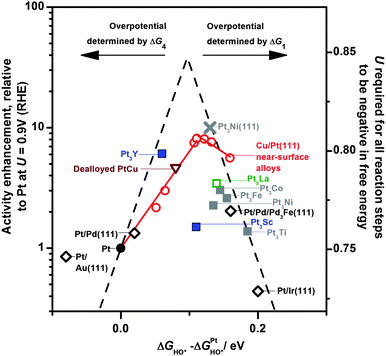

*Figure: Literature volcano for catalysts with Pt overlayers.*

The Pt90Ni10 distribution sits closer to this reference optimum in our calculation. Let us read that as a descriptor comparison; activity still depends on the full reaction pathway and experiment.


## Student exercise: Read the full distribution

Inspect the optimized structure and the energy shown above. Which change in geometry or energy matters for the chemical question in this section?

In [ ]:
# Your code here.
# Use a separate variable for your changed parameter and display the comparison.

### Your answer

Prediction: [write your prediction]

Result: [report a value or refer to your figure]

Chemical explanation: [explain the result]

Assumption or limitation: [state one limitation]


## What have you learned

Let us gather the main ideas from this notebook. You can now:

- Build alloy slabs with a chosen composition and a Pt skin.
- Create a reproducible set of local atomic arrangements.
- Calculate and read OH adsorption energy distributions.
- Explain what a distribution tells us beyond its mean descriptor.


### Questions for discussion

1. Could two alloy samples share the same mean OH binding energy and still show different catalytic behavior? Explain your reasoning.
2. What calculation checks could separate a composition effect from incomplete relaxation or a small configuration sample?
